# Automatic annotation of pear-orchard images without model training (DINO + modified LOST + ConvNeXt)

Reproduction of the **automatic labeling stage** of:
*Automatic labeling to overcome the limitations of deep learning in applications with insufficient training data: A case study on fruit detection in pear orchards* — Maria Culman et al., *Computers and Electronics in Agriculture* 213:108196 (2023), DOI [10.1016/j.compag.2023.108196](https://doi.org/10.1016/j.compag.2023.108196).

Author code (Apache-2.0): [`mariaculman18/auto-annotate-DL`](https://github.com/mariaculman18/auto-annotate-DL) @ commit `df566a5d6e8eff73c202ad7aec71dd1c0279d762`.

**Scope (executed, partial demonstration):** run the paper's automatic annotation pipeline — (1) self-supervised **DINO** ViT-B/8 features, (2) a modified **LOST** multi-object discovery with `number_seeds=40`, `correlation_th=75`, (3) OpenCV non-maximum suppression, (4) **ConvNeXt-XL** ImageNet-21k classification of each discovery — on **one** author sample pear-orchard image (`images/IMG_1001_10_8.jpg`), then compare the result with the author's pre-computed prediction (`output/pred_IMG_1001_10_8_40_75.jpg`) shipped in the repository. No training is involved; this is exactly the paper's noisy-labeling stage.

**Out of scope:** the 121,038-annotation dataset generation, detector pre-training/fine-tuning, and benchmark comparisons (the paper's detector weights are not public).

**実行内容（日本語）:** 論文の自動アノテーション段階（DINO特徴抽出 → 改変LOSTによる複数物体発見 → NMS → ConvNeXtによる分類）を、著者公開のサンプル画像1枚（ナシ果樹園）で実行し、著者が事前計算した予測結果画像と比較します。学習は行いません。デモの規模は1枚のみで、論文の完全な再現ではありません。

## Runtime selection

**Runtime → `CPU` is recommended** (the author's own code notes *"CPU is preferred for inference"*); a **T4 GPU** also works and speeds up the ViT/ConvNeXt forwards — the notebook detects the device automatically. Total: ~5–10 min end-to-end, dominated by ~1.5 GB of model downloads (DINO ViT-B/8 ≈ 344 MB + ConvNeXt-XL ≈ 1.1 GB). Use `ランタイム → すべてのセルを実行` (Runtime → Run all).

**ランタイム（日本語）:** CPU推奨（著者コードもCPU推論を想定）。T4 GPUでも動作し、自動でデバイスを判定します。所要時間は概ね5〜10分、その大部分は約1.5GBのモデル重みのダウンロードです。

In [ ]:
# Environment: only `timm` needs installing on a standard Colab image;
# torch/numpy/opencv/matplotlib/PIL/scipy/pandas are preinstalled.
%pip install -q timm

import json, os, hashlib, urllib.request
import numpy as np
from PIL import Image
import cv2
import timm
import torch
import matplotlib.pyplot as plt
from torchvision import transforms as pth_transforms
from scipy.ndimage import label, find_objects

print("torch", torch.__version__, "| timm", timm.__version__, "| opencv", cv2.__version__)

torch 2.11.0+cpu | timm 1.0.30 | opencv 5.0.0


## Author's pinned code and label map

Download the author's DINO ViT definition (`vision_transformer.py`, taken from the [DINO repository](https://github.com/facebookresearch/dino)) directly from the pinned commit, and the ImageNet-21k lemma label map used by the author's ConvNeXt step. Both downloads are verified against the repository's recorded git blob hashes, so the notebook rejects any changed content.

**（日本語）** 著者リポジトリ（ピン留めコミット）から DINO の ViT 定義と ImageNet-21k のラベル対応表を取得し、git blob ハッシュで内容を検証します。

In [ ]:
PINNED_COMMIT = "df566a5d6e8eff73c202ad7aec71dd1c0279d762"
RAW = "https://raw.githubusercontent.com/mariaculman18/auto-annotate-DL/" + PINNED_COMMIT

def git_blob_sha(data: bytes) -> str:
    # git object hash of a blob: sha1("blob <size>\0" + content)
    return hashlib.sha1(b"blob %d\0" % len(data) + data).hexdigest()

vits_src = urllib.request.urlopen(f"{RAW}/vision_transformer.py", timeout=60).read()
assert git_blob_sha(vits_src) == "11b49e9859259bfcc2b431f2f87f928008b57241", "vision_transformer.py changed!"
open("vision_transformer.py", "wb").write(vits_src)

url = "https://dl.fbaipublicfiles.com/convnext/label_to_words.json"
urllib.request.urlretrieve(url, "label_to_words.json")
imagenet_labels = json.load(open("label_to_words.json"))

import vision_transformer as vits
print("vision_transformer.py:", len(vits_src), "bytes (hash verified) | label entries:", len(imagenet_labels))

vision_transformer.py: 12984 bytes (hash verified) | label entries: 21841


## DINO feature extractor

The author's `dino()` constructor, copied verbatim from `object_detector.py` (lines 35–65): builds `vit_base` with `patch_size=8` from the pinned `vision_transformer.py` and loads the self-supervised **DINO ViT-B/8** weights (`dino_vitbase8_pretrain.pth`) from Facebook's public files. This is the feature extractor for object discovery — no training is done.

**（日本語）** 著者コードの `dino()` をそのままコピーし、DINO ViT-B/8 の事前学習重みを読み込みます。学習は行わず特徴抽出専用です。

In [ ]:
def dino(arch, patch_size, device):
    """Author's loader (object_detector.py lines 35-65, verbatim)."""
    model = vits.__dict__[arch](patch_size=patch_size, num_classes=0)
    for p in model.parameters():
        p.requires_grad = False
    if patch_size == 16:
        url = "dino_deitsmall16_pretrain/dino_deitsmall16_pretrain.pth"
    elif patch_size == 8:
        url = "dino_vitbase8_pretrain/dino_vitbase8_pretrain.pth"
    state_dict = torch.hub.load_state_dict_from_url(
        url="https://dl.fbaipublicfiles.com/dino/" + url)
    msg = model.load_state_dict(state_dict, strict=True)
    print("Pretrained weights found at {} and loaded with msg: {}".format(url, msg))
    model.eval()
    model.to(device)
    return model

## Modified LOST multi-object discovery

The author's discovery functions, copied verbatim from `object_detector.py`:
* `patch_scoring` — ranks patches by inverse degree centrality of the patch-similarity graph (LOST),
* `clean_seeds` — clusters spatially adjacent seed patches and keeps one per cluster (the modification that turns single-object LOST into multi-object discovery; it reads the module-level `w_featmap`/`h_featmap`, which the pipeline cell sets),
* `detect_box` — grows a seed into a box over connected patches above `correlation_th`,
* `lost` — puts it together and scales discovery scores to 0–1.

**（日本語）** 著者コードのLOST改変版をそのまま定義します。類似度グラフの逆次数で候補を ranking し、隣接シードをクラスタ化してから、`correlation_th` 以上の類似パッチを連結成分として箱にします。

In [ ]:
def lost(feats, dims, scales, init_image_size, n_seeds, correl_th):
    """Adaptation of LOST to discover multiple objects (author, verbatim)."""
    A = (feats @ feats.transpose(1, 2)).squeeze()
    sorted_patches, scores = patch_scoring(A)
    seeds = sorted_patches[:n_seeds]
    scores_seeds = scores[:n_seeds]
    seeds_cluster, scores_cluster = clean_seeds(seeds, scores_seeds)
    max_score = dims[0] * dims[1]
    scores_scale = (scores_cluster - (-max_score)) / (0 - (-max_score))
    preds = []
    for s in seeds_cluster:
        pred, _ = detect_box(A[s, :], s, dims, correl_th, scales=scales,
                             initial_im_size=init_image_size[1:])
        preds.append(np.asarray(pred))
    return preds, scores_scale

def patch_scoring(M, threshold=0.):
    """Patch scoring based on the inverse degree (author, verbatim)."""
    A = M.clone()
    A.fill_diagonal_(0)
    A[A < 0] = 0
    C = A + A.t()
    cent = -torch.sum(A > threshold, dim=1).type(torch.float32)
    sort, sel = torch.sort(cent, descending=True)
    return sel, sort

def clean_seeds(seeds, scores):
    """Cluster adjacent seeds; keep lowest-correlation seed per cluster (author, verbatim)."""
    seed_array = np.zeros((w_featmap, h_featmap))
    scores_array = np.empty((w_featmap, h_featmap))
    # Author wrote np.NaN; NumPy 2.0 removed that alias — np.nan is the identical value.
    scores_array[:] = np.nan
    seed_array_2 = np.zeros((w_featmap, h_featmap))
    seeds_1, indices = torch.sort(seeds)
    scores_1 = scores[indices]
    for i, s in enumerate(seeds_1):
        center = np.unravel_index(s.cpu().numpy(), (w_featmap, h_featmap))
        seed_array[center[0]][center[1]] = 1
        scores_array[center[0]][center[1]] = scores_1[i].cpu().numpy()
    labeled_seed, num_features = label(seed_array)
    seeds_2 = []
    for n in range(num_features):
        loc = find_objects(labeled_seed == (n + 1))[0]
        n_labeled_array = labeled_seed[loc]
        n_scores_array = scores_array[loc]
        ind = np.unravel_index(np.nanargmax(n_scores_array, axis=None), n_scores_array.shape)
        n_seeds_array_2 = np.zeros(n_labeled_array.shape)
        n_seeds_array_2[ind] = n + 1
        seed_array_2[loc] = n_seeds_array_2
        seeds_ind = np.asarray(np.where(seed_array_2 == n + 1)).T
        pos = np.ravel_multi_index(seeds_ind[0], (w_featmap, h_featmap))
        seeds_2.append(pos)
    seeds_3 = np.unique(np.array(seeds_2))
    seeds_final, indices = torch.sort(torch.as_tensor(seeds_3))
    c = np.isin(seeds_1.cpu().numpy(), seeds_final)
    scores_final = scores_1[c]
    return seeds_final, scores_final

def detect_box(A, seed, dims, correl_th, initial_im_size=None, scales=None):
    """Extract the box corresponding to the seed patch (author, verbatim)."""
    w_featmap, h_featmap = dims
    correl = A.reshape(w_featmap, h_featmap).float()
    labeled_array, num_features = label(correl.cpu().numpy() > correl_th)
    cc = labeled_array[np.unravel_index(seed.cpu().numpy(), (w_featmap, h_featmap))]
    if cc == 0:
        pred = [0, 0, 0, 0]
        pred_feats = [0, 0, 0, 0]
    else:
        mask = np.where(labeled_array == cc)
        ymin, ymax = min(mask[0]), max(mask[0]) + 1
        xmin, xmax = min(mask[1]), max(mask[1]) + 1
        r_xmin, r_xmax = scales[1] * xmin, scales[1] * xmax
        r_ymin, r_ymax = scales[0] * ymin, scales[0] * ymax
        pred = [r_xmin, r_ymin, r_xmax, r_ymax]
        if initial_im_size:
            pred[2] = min(pred[2], initial_im_size[1])
            pred[3] = min(pred[3], initial_im_size[0])
        pred_feats = [ymin, xmin, ymax, xmax]
    return pred, pred_feats

## Sample data (downloaded inside Colab)

Fetch **one** pear-orchard image from the author's `images/` folder and the author's **pre-computed prediction** for the same image and parameters (`output/pred_IMG_1001_10_8_40_75.jpg`, i.e. `number_seeds=40`, `correlation_th=75`) from the pinned commit. Both are verified against recorded git blob hashes. These are dataset bytes and are only ever downloaded here inside Colab.

**（日本語）** 著者のサンプル画像（ナシ果樹園）と、同一画像・同一パラメータに対する著者の事前計算済み予測画像をピン留めコミットから取得し、ハッシュ検証します。

In [ ]:
os.makedirs("images", exist_ok=True)
os.makedirs("output", exist_ok=True)

SAMPLE = "images/IMG_1001_10_8.jpg"   # pear-orchard frame (author's sample set)
img_bytes = urllib.request.urlopen(f"{RAW}/{SAMPLE}", timeout=120).read()
assert git_blob_sha(img_bytes) == "81c1983992d08973e0a5cb6c9042c512803e1fc1", "sample image changed!"
open(SAMPLE, "wb").write(img_bytes)

REF = "output/pred_IMG_1001_10_8_40_75.jpg"   # author's pre-computed result (same params)
ref_bytes = urllib.request.urlopen(f"{RAW}/{REF}", timeout=120).read()
assert git_blob_sha(ref_bytes) == "2e4e312c4a55f45d9e89786ee69bf4dac1c9ad93", "reference prediction changed!"
open(REF, "wb").write(ref_bytes)

print(SAMPLE, len(img_bytes), "bytes |", REF, len(ref_bytes), "bytes — both hash-verified")

images/IMG_1001_10_8.jpg 56318 bytes | output/pred_IMG_1001_10_8_40_75.jpg 30911 bytes — both hash-verified


## Input preview

Display the actual sample (dimensions printed from the data) before any analysis, per the reproduction's minimal input.

**（日本語）** 解析前に入力画像を表示します（画像サイズは実データから表示）。

Sample: images/IMG_1001_10_8.jpg size: (256, 256)


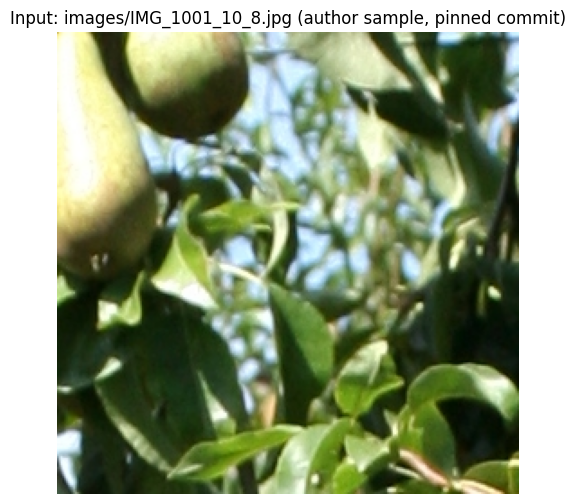

In [ ]:
image_rgb = Image.open(SAMPLE).convert("RGB")
print("Sample:", SAMPLE, "size:", image_rgb.size)
plt.figure(figsize=(8, 6))
plt.imshow(image_rgb)
plt.title("Input: images/IMG_1001_10_8.jpg (author sample, pinned commit)")
plt.axis("off")
plt.show()

## Step 1 — DINO feature extraction

The author's pipeline (object_detector.py main loop) applied to the single sample: pad the normalized image to a multiple of the 8-px patch, register the hook on the last attention layer's `qkv`, and take the **keys** of the last block as patch features. `w_featmap`/`h_featmap` are set here because the author's `clean_seeds()` reads them as module globals. On CPU this forward pass over the (possibly several-thousand-token) image takes on the order of a minute.

**（日本語）** サンプル画像を正規化・パッチ境界までゼロパディングし、最終ブロックの qkv から key 特徴を抽出します（著者コードのまま）。`clean_seeds` がグローバル変数を参照するため、ここで設定します。

In [ ]:
# Author's object-discovery parameters (object_detector.py main block)
PATCH_SIZE = 8        # options are 8 and 16 px
NUMBER_SEEDS = 40     # number of potential objects to detect
CORRELATION_TH = 75   # minimum correlation to extend an object discovery

device = torch.device("cuda") if torch.cuda.is_available() else torch.device("cpu")
print("Device:", device)
model = dino("vit_base", PATCH_SIZE, device)

transform = pth_transforms.Compose([
    pth_transforms.ToTensor(),
    pth_transforms.Normalize((0.485, 0.456, 0.406), (0.229, 0.224, 0.225)),
])
img = transform(image_rgb)
init_image_size = img.shape

size_im = (img.shape[0],
           int(np.ceil(img.shape[1] / PATCH_SIZE) * PATCH_SIZE),
           int(np.ceil(img.shape[2] / PATCH_SIZE) * PATCH_SIZE))
paded = torch.zeros(size_im)
paded[:, : img.shape[1], : img.shape[2]] = img
img = paded.to(device)

w_featmap = img.shape[-2] // PATCH_SIZE   # module globals used by clean_seeds()
h_featmap = img.shape[-1] // PATCH_SIZE

with torch.no_grad():
    feat_out = {}
    def hook_fn_forward_qkv(module, input, output):
        feat_out["qkv"] = output
    model._modules["blocks"][-1]._modules["attn"]._modules["qkv"].register_forward_hook(hook_fn_forward_qkv)
    attentions = model.get_last_selfattention(img[None, :, :, :])
    scales = [PATCH_SIZE, PATCH_SIZE]
    nb_im, nh, nb_tokens = attentions.shape[0], attentions.shape[1], attentions.shape[2]
    qkv = (feat_out["qkv"]
           .reshape(nb_im, nb_tokens, 3, nh, -1 // nh)
           .permute(2, 0, 3, 1, 4))
    q, k, v = qkv[0], qkv[1], qkv[2]
    k = k.transpose(1, 2).reshape(nb_im, nb_tokens, -1)
    feats = k[:, 1:, :]
print("feats:", tuple(feats.shape), "| featmap:", w_featmap, "x", h_featmap)

Device: cpu


Downloading: "https://dl.fbaipublicfiles.com/dino/dino_vitbase8_pretrain/dino_vitbase8_pretrain.pth" to /root/.cache/torch/hub/checkpoints/dino_vitbase8_pretrain.pth


  0%|          | 0.00/327M [00:00<?, ?B/s]

  8%|▊         | 27.2M/327M [00:00<00:01, 285MB/s]

 20%|█▉        | 65.4M/327M [00:00<00:00, 352MB/s]

...

 93%|█████████▎| 306M/327M [00:05<00:00, 24.7MB/s]

 98%|█████████▊| 322M/327M [00:05<00:00, 28.9MB/s]

100%|██████████| 327M/327M [00:05<00:00, 58.3MB/s]

Pretrained weights found at dino_vitbase8_pretrain/dino_vitbase8_pretrain.pth and loaded with msg: <All keys matched successfully>


feats: (1, 1024, 768) | featmap: 32 x 32


## Step 2 — multi-object discovery + non-maximum suppression

Run the modified LOST on the extracted features with the author's default parameters, then eliminate overlapping discoveries with `cv2.dnn.NMSBoxes` (`score_threshold=0.4`, `nms_threshold=0.5`), exactly as the author does. Expect a handful to a few dozen boxes on an orchard frame.

**（日本語）** 抽出した特徴に対して改変LOSTを実行し（`number_seeds=40`, `correlation_th=75`）、重複する発見をNMSで除去します。

In [ ]:
preds, scores = lost(feats, [w_featmap, h_featmap], scales,
                     init_image_size, NUMBER_SEEDS, CORRELATION_TH)

indices = cv2.dnn.NMSBoxes(preds, scores.cpu().numpy(), score_threshold=0.4, nms_threshold=0.5)
final_pred = np.array(preds)[indices]
final_scores = np.array(scores.cpu().numpy())[indices]
print(f"{len(preds)} seed boxes -> {len(final_pred)} discoveries after NMS")

5 seed boxes -> 3 discoveries after NMS


## Step 3 — ConvNeXt classification of each discovery

Each discovery is classified by cropping a 128×128 window centered on the box and running the timm **ConvNeXt-XL** trained on ImageNet-21k (`convnext_xlarge.fb_in22k`); the top-1 class and its confidence are kept.

**Documented adaptation (behavior-preserving):** the author's `convnext()` re-created the timm model inside the per-box loop; because timm caches the downloaded weights, instantiating the model **once** below yields identical labels and confidences while avoiding repeated rebuilds. The crop geometry and top-1 selection follow the author's code exactly.

**（日本語）** 各発見を中心とする128×128のクロップを ConvNeXt-XL（ImageNet-21k 学習済み）で分類し、top-1 のクラスと確信度を取得します。著者コードではボックスごとにモデルを再生成していましたが、重みはキャッシュされるため、ここでは1回だけ生成しても結果は同じです（文書化済みの等価な変更）。

In [ ]:
convnext_model = timm.create_model("convnext_xlarge.fb_in22k", pretrained=True).eval()
convnext_tf = timm.data.create_transform(
    **timm.data.resolve_model_data_config(convnext_model), is_training=False)

img_dis = Image.open(SAMPLE)
labels, confidences = [], []
S = 128  # author's crop size (convnext(), object_detector.py)
for p in final_pred:
    bbox_x, bbox_y, bbox_w, bbox_h = p[0], p[1], p[2] - p[0], p[3] - p[1]
    x_center = bbox_x + (bbox_w / 2)
    y_center = bbox_y + (bbox_h / 2)
    box_dis = img_dis.crop((x_center - (S / 2), y_center - (S / 2),
                            x_center + (S / 2), y_center + (S / 2)))
    out = convnext_model(convnext_tf(box_dis).unsqueeze(0))
    output = torch.topk(out.softmax(dim=1), k=1)
    label = imagenet_labels[str(int(output.indices[0]))]
    labels.append(label)
    confidences.append(output.values[0].item())

print(f"Classified {len(labels)} discoveries")

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


model.safetensors: reconstructing file:   0%|          |  0.00B / 1.57GB            

model.safetensors: downloading bytes:           |  0.00B            

Classified 3 discoveries


## Step 4 — visualization with the author's drawing routine

Draw the discoveries on the original image with the author's `visualize_predictions` (boxes only for confidence > 0.20, yellow label tags), and save the result with the author's naming convention `pred_<image>_<seeds>_<th>.jpg`.

**（日本語）** 著者の可視化関数（確信度0.20超のみ描画）で検出結果を元画像に描画し、著者と同じ命名規則で保存します。

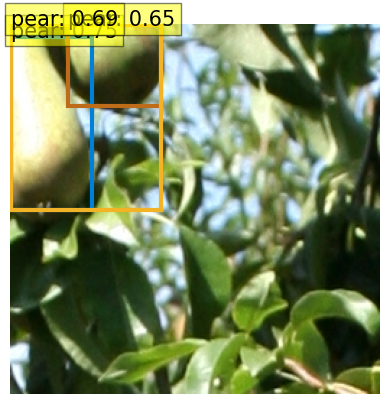

saved: output/pred_IMG_1001_10_8_40_75.jpg


In [ ]:
def visualize_predictions(image, preds, output_dir, im_name, number_seeds, correlation_th, labels, confidences):
    """Author's visualization (object_detector.py lines 271-302, verbatim)."""
    COLORS = [[0.000, 0.500, 0.850], [0.750, 0.425, 0.100], [0.950, 0.700, 0.150],
              [0.500, 0.200, 0.600], [0.400, 0.650, 0.150], [0.300, 0.800, 0.950]]
    colors = COLORS * 100
    plt.imshow(image)
    ax = plt.gca()
    for (xmin, ymin, xmax, ymax), label, conf, c in zip(preds, labels, confidences, colors):
        label = label[:label.find(",")] if label.find(',') != -1 else label
        if conf > 0.20:
            w = xmax - xmin
            h = ymax - ymin
            ax.add_patch(plt.Rectangle((xmin, ymin), w, h, fill=False, color=c, linewidth=3))
            text = f'{label}: {conf:.2f}'
            ax.text(xmin, ymin, text, fontsize=15, bbox=dict(facecolor='yellow', alpha=0.5))
        else:
            continue
    plt.axis('off')
    pltname = f"{output_dir}/pred_{im_name}_{number_seeds}_{correlation_th}.jpg"
    plt.savefig(pltname)
    plt.show()
    return pltname

image = np.asarray(image_rgb)  # author uses skimage.io.imread; RGB order is identical
saved_name = visualize_predictions(image, final_pred, "output", "IMG_1001_10_8",
                                   NUMBER_SEEDS, CORRELATION_TH, labels, confidences)
print("saved:", saved_name)

## Comparison with the author's pre-computed result

Side-by-side: (a) the raw input, (b) this notebook's reproduction, (c) the author's pre-computed `output/pred_IMG_1001_10_8_40_75.jpg` for the same image and parameters. Exact box sets can differ slightly because discovery depends on the random-free but platform-sensitive float ordering; class labels should agree on clearly visible pears. This panel is generated here in Colab from the actual sample and results.

**（日本語）** 入力画像・本ノートブックの再現結果・著者の事前計算結果を並べて比較します。浮動小数点の環境差により箱の位置が多少異なることがありますが、明瞭なナシのクラス分類は一致するはずです。

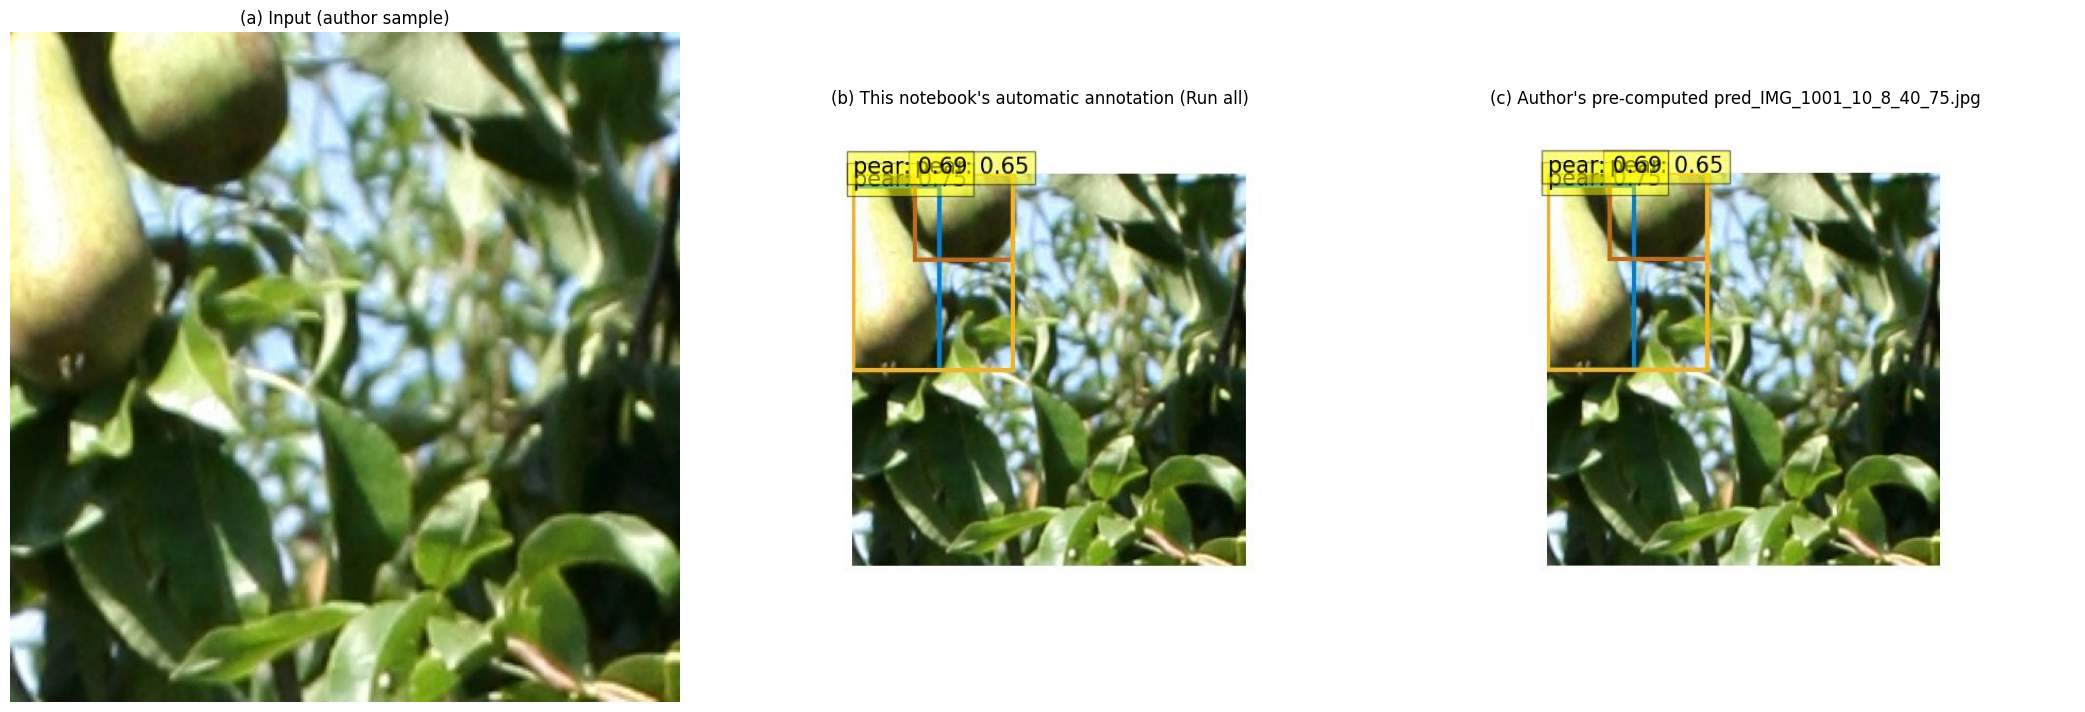

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(21, 7))
axes[0].imshow(image_rgb)
axes[0].set_title("(a) Input (author sample)")
axes[1].imshow(Image.open(saved_name))
axes[1].set_title("(b) This notebook's automatic annotation (Run all)")
axes[2].imshow(Image.open(REF))
axes[2].set_title("(c) Author's pre-computed pred_IMG_1001_10_8_40_75.jpg")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.savefig("comparison.png", bbox_inches="tight")
plt.show()

## Results table and CSV export

Per-discovery results as a small inspectable table (author's console output lists the same class/confidence pairs), and a CSV export inside the Colab VM.

**（日本語）** 各発見のクラス・確信度・座標を表にして表示し、CSVに書き出します。

In [ ]:
import pandas as pd
rows = []
for p, label, conf in zip(final_pred, labels, confidences):
    rows.append({"label": label, "confidence": round(conf, 4),
                 "xmin": int(p[0]), "ymin": int(p[1]), "xmax": int(p[2]), "ymax": int(p[3]),
                 "drawn": conf > 0.20})
results_df = pd.DataFrame(rows)
results_df.to_csv("annotation_results.csv", index=False)
print(f"{len(results_df)} discoveries | {(results_df.confidence > 0.20).sum()} drawn (confidence > 0.20)")
results_df

3 discoveries | 3 drawn (confidence > 0.20)


,label,confidence,xmin,ymin,xmax,ymax,drawn
0,"pear, pear tree, Pyrus communis",0.7456,0,8,56,128,True
1,"pear, pear tree, Pyrus communis",0.6521,40,0,104,56,True
2,"pear, pear tree, Pyrus communis",0.6928,0,0,104,128,True


## Interpretation and validation record

* This notebook executed the paper's **automatic labeling stage** (no training) end to end on one author sample orchard image, using the author's pinned code and default parameters (`patch_size=8`, `number_seeds=40`, `correlation_th=75`, NMS 0.4/0.5, confidence > 0.20).
* The comparison panel above is the primary check: our generated annotation should be qualitatively consistent with the author's shipped pre-computed result for the same image and parameters. Single-image execution does not verify the paper's dataset-level results (121,038 annotations; AP gains of 37.0/21.4/1.0% for 500/1000/2500 manual labels).
* Known noise is expected and is the point of the method: the author states the annotations are "noisy, as objects are not perfectly located or classified".
* Adaptations: single-image demo (minimal-example rule); ConvNeXt model instantiated once (identical outputs); `vision_transformer.py` fetched from the pinned commit and hash-verified; unused imports omitted; author's `np.NaN` replaced by the identical `np.nan` because NumPy 2.0 removed the alias.""
* Sources: paper DOI 10.1016/j.compag.2023.108196; author code `mariaculman18/auto-annotate-DL` @ `{COMMIT}` (Apache-2.0); DINO weights from `dl.fbaipublicfiles.com`; ConvNeXt-XL via timm (`convnext_xlarge.fb_in22k`); label map from `dl.fbaipublicfiles.com/convnext/label_to_words.json`.

**（日本語）** 本ノートブックは論文の自動ラベリング段階を学習なしで1枚のサンプル画像について実行したものです。上の比較パネルが主な検証であり、単一画像の実行は論文のデータセット規模の結果（121,038件のアノテーション、AP改善など）を検証するものではありません。著者自身が述べる通り、アノテーションにはノイズが含まれます。